FIRST 5 ROWS
   No  X1 transaction date  X2 house age  \
0   1             2012.917          32.0   
1   2             2012.917          19.5   
2   3             2013.583          13.3   
3   4             2013.500          13.3   
4   5             2012.833           5.0   

   X3 distance to the nearest MRT station  X4 number of convenience stores  \
0                                84.87882                               10   
1                               306.59470                                9   
2                               561.98450                                5   
3                               561.98450                                5   
4                               390.56840                                5   

   X5 latitude  X6 longitude  Y house price of unit area  
0     24.98298     121.54024                        37.9  
1     24.98034     121.53951                        42.2  
2     24.98746     121.54391                        47.3  
3     24.98746   

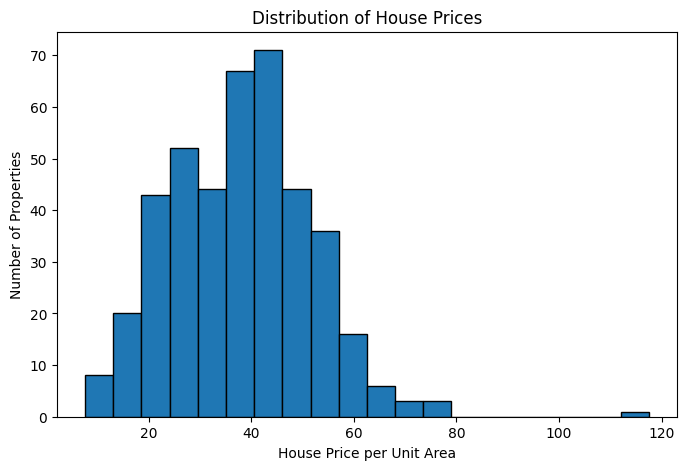

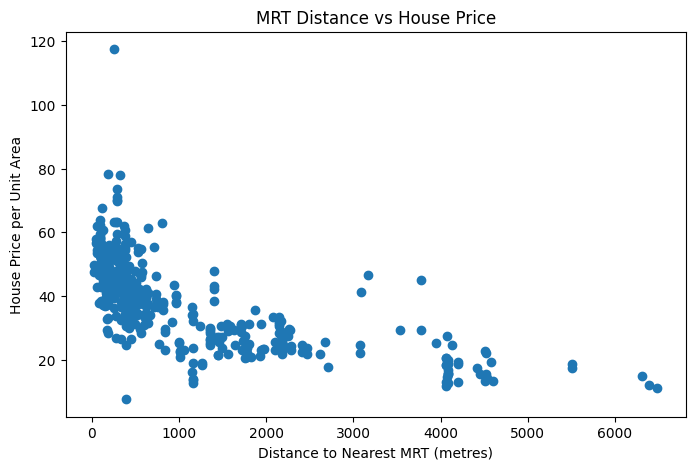


OBSERVATIONS
1. The average and median house price help describe
   the overall price distribution.
2. Average prices differ between properties within
   1000 metres of an MRT station and properties
   farther than 1000 metres.
3. Average prices also differ between properties
   with fewer than 5 convenience stores and those
   with 5 or more nearby stores.

EDA COMPLETED


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
url = "https://raw.githubusercontent.com/utsav2110/IE494_BDP_Lab7/main/data/real_estate.csv"

df = pd.read_csv(url)

# 2. Display basic information
print("FIRST 5 ROWS")
print(df.head())

print("\nLAST 5 ROWS")
print(df.tail())

print("\nDATASET SHAPE")
print(df.shape)

print("\nDATASET INFORMATION")
df.info()

print("\nDESCRIPTIVE STATISTICS")
print(df.describe())

# 3. Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 4. Check duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 5. Rename columns for easier use
df.columns = [
    "Transaction_Date",
    "House_Age",
    "MRT_Distance",
    "Convenience_Stores",
    "Latitude",
    "Longitude",
    "House_Price"
]

# 6. NumPy array calculations for house price
price_array = np.array(df["House_Price"])

print("\nHOUSE PRICE STATISTICS USING NUMPY")
print("Average:", np.mean(price_array))
print("Median:", np.median(price_array))
print("Minimum:", np.min(price_array))
print("Maximum:", np.max(price_array))

# 7. Average house age
print("\nAVERAGE HOUSE AGE")
print(df["House_Age"].mean())

# 8. Compare properties near and far from MRT
# Threshold chosen: 1000 metres

df["MRT_Category"] = np.where(
    df["MRT_Distance"] <= 1000,
    "Near MRT",
    "Far from MRT"
)

print("\nPROPERTY COUNT BY MRT CATEGORY")
print(df["MRT_Category"].value_counts())

print("\nAVERAGE PRICE BY MRT CATEGORY")
print(df.groupby("MRT_Category")["House_Price"].mean())

# 9. Compare prices based on convenience stores
# Group: fewer than 5 stores and 5 or more stores

df["Store_Category"] = np.where(
    df["Convenience_Stores"] >= 5,
    "5 or more stores",
    "Fewer than 5 stores"
)

print("\nPROPERTY COUNT BY STORE CATEGORY")
print(df["Store_Category"].value_counts())

print("\nAVERAGE PRICE BY STORE CATEGORY")
print(df.groupby("Store_Category")["House_Price"].mean())

# 10. Find top 10 highest-priced records
top_10 = df.sort_values(
    by="House_Price",
    ascending=False
).head(10)

print("\nTOP 10 HIGHEST-PRICED RECORDS")
print(top_10)

# 11. House price histogram
plt.figure(figsize=(8, 5))
plt.hist(df["House_Price"], bins=20, edgecolor="black")
plt.title("Distribution of House Prices")
plt.xlabel("House Price per Unit Area")
plt.ylabel("Number of Properties")
plt.show()

# 12. Scatter plot: MRT distance vs house price
plt.figure(figsize=(8, 5))
plt.scatter(df["MRT_Distance"], df["House_Price"])
plt.title("MRT Distance vs House Price")
plt.xlabel("Distance to Nearest MRT (metres)")
plt.ylabel("House Price per Unit Area")
plt.show()

# 13. Three observations
print("\nOBSERVATIONS")

print("1. The average and median house price help describe")
print("   the overall price distribution.")

print("2. Average prices differ between properties within")
print("   1000 metres of an MRT station and properties")
print("   farther than 1000 metres.")

print("3. Average prices also differ between properties")
print("   with fewer than 5 convenience stores and those")
print("   with 5 or more nearby stores.")

print("\nEDA COMPLETED")